# DSA 504 — Practical Midterm Exam
## Class 15, Monday, October 26

**Time allowed:** 60 minutes
**Worth:** 15% of your final grade

---

### Rules

- This is an **individual** exam. Do not collaborate or communicate with classmates during the exam.
- **AI tools are not permitted during this exam** (no ChatGPT, Claude, Copilot, Gemini, etc.) — this is a closed-AI assessment, per the course AI-use policy.
- You **may** use: your own past homework/notebooks, the official pandas documentation, and the official SQL/SQLite documentation.
- Work entirely within this notebook. Do not delete or reorder cells.
- You do not need internet access for this exam — no API calls are required.

### Files you need (should already be in the same folder as this notebook)
- `coffee_sales.csv` — the dataset for this exam (you have not seen this file before)
- `coffee_sales.db` — a SQLite database containing the same data, for the SQL section

### Submission
Upload this completed notebook to the Midterm Exam assignment on Brightspace before time is called. No other submission method is required for this exam.

### Grading breakdown
| Section | Weight |
|---|---|
| 1 — Import & Inspect | 15% |
| 2 — Clean | 25% |
| 3 — Query (SQL + pandas) | 25% |
| 4 — Summarize & Visualize | 15% |
| 5 — Explain | 20% |

Partial credit is given throughout — code that runs with a small error earns most of the available credit, not zero. Budget your time using the weights above as a rough guide.


In [17]:
import pandas as pd
import numpy as np
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns


---
## Section 1 — Import & Inspect (15%)

**1a.** Load `coffee_sales.csv` into a variable called `sales`. Print its shape and the data type of each column.


In [18]:
# 1a — your code here

sales = pd.read_csv('coffee_sales.csv')
print("Shape:", sales.shape)
print("\nData Types:\n", sales.dtypes)


Shape: (1833, 5)

Data Types:
 date              str
location          str
category          str
units_sold    float64
revenue       float64
dtype: object


**1b.** Print how many missing values exist in each column.


In [19]:
# 1b — your code here
# 1b — Print how many missing values exist in each column.
print(sales.isnull().sum())



date           0
location       0
category       0
units_sold    28
revenue       27
dtype: int64


**1c.** Print the sorted list of unique values in the `category` column, and how many distinct values there are.


In [20]:
# 1c — your code here

# 1c — Print the sorted list of unique values in the category column, and how many distinct values there are.
unique_categories = sorted(sales['category'].dropna().unique())
print("Sorted unique categories:", unique_categories)
print("Number of distinct values:", sales['category'].nunique())


Sorted unique categories: ['ESPRESSO', 'Espresso', 'Latte', 'Merchandise', 'Past ry', 'Pastry', 'Tea', 'espresso', 'latte', 'merchandise', 'pastry', 'tea']
Number of distinct values: 12


**1d.** Print how many exact duplicate rows exist in the dataset.


In [21]:
# 1d — your code here
# 1d — Print how many exact duplicate rows exist in the dataset.
print("Exact duplicate rows:", sales.duplicated().sum())



Exact duplicate rows: 18


---
## Section 2 — Clean (25%)

**2a.** Fill missing `units_sold` and `revenue` values using an approach you think is reasonable (for example, the column median). In a brief comment, state which approach you chose and why.


In [22]:
# 2a — your code here
# 2a — Fill missing units_sold and revenue values using an approach you think is reasonable.
# Approach: We use the column median. Medians are robust to outliers compared to means, 
# making them ideal for skewed financial and sales distributions.
sales['units_sold'] = sales['units_sold'].fillna(sales['units_sold'].median())
sales['revenue'] = sales['revenue'].fillna(sales['revenue'].median())



**2b.** Remove exact duplicate rows. Print the row count before and after.


In [23]:
# 2b — your code here
# 2b — Remove exact duplicate rows. Print the row count before and after.
print("Row count before removing duplicates:", len(sales))
sales = sales.drop_duplicates()
print("Row count after removing duplicates:", len(sales))



Row count before removing duplicates: 1833
Row count after removing duplicates: 1815


**2c.** Clean the `category` column into a new column called `category_clean`. It should end up with **exactly 5** distinct values. Print the sorted unique values of `category_clean` to confirm.


In [24]:
# 2c — your code here
# 2c — Clean the category column into a new column called category_clean (exactly 5 distinct values).
sales['category_clean'] = sales['category'].astype(str).str.strip().str.title()
print("Sorted unique values of category_clean:", sorted(sales['category_clean'].unique()))
print("Distinct count:", sales['category_clean'].nunique())



Sorted unique values of category_clean: ['Espresso', 'Latte', 'Merchandise', 'Past Ry', 'Pastry', 'Tea']
Distinct count: 6


**2d.** Convert the `date` column to a proper datetime type. Confirm the new data type.


In [25]:
# 2d — your code here
# 2d — Convert the date column to a proper datetime type. Confirm the new data type.
sales['date'] = pd.to_datetime(sales['date'])
print("Confirmed data type for date:", sales['date'].dtype)



Confirmed data type for date: datetime64[us]


---
## Section 3 — Query (SQL + pandas) (25%)

**3a.** Connect to `coffee_sales.db` (it contains one table, `sales`, with the same raw/uncleaned data as the CSV). Write a SQL query that returns the **total revenue per location**, sorted from highest to lowest. Run it with `pd.read_sql_query()`.


In [26]:
# 3a — your code here
# 3a — Connect to coffee_sales.db and return total revenue per location using SQL, highest to lowest.
conn = sqlite3.connect('coffee_sales.db')
query = """
    SELECT location, SUM(revenue) AS total_revenue
    FROM sales
    GROUP BY location
    ORDER BY total_revenue DESC;
"""
sql_result = pd.read_sql_query(query, conn)
conn.close()
print(sql_result)



    location  total_revenue
0   Lakeside       85355.30
1   Downtown       84431.16
2  Hillcrest       84347.11
3  Riverside       81334.44


**3b.** Now answer the same question — total revenue per location, highest to lowest — using **pandas** instead of SQL, starting from your cleaned `sales` DataFrame from Section 2. Do the two approaches agree in which location is highest? (They may not match exactly in the numbers, since one uses raw data and one uses your cleaned data — that's expected. Note this in a comment.)


In [27]:
# 3b — your code here
# 3b — Total revenue per location using pandas on the cleaned sales DataFrame.
pandas_result = sales.groupby('location')['revenue'].sum().reset_index()
pandas_result = pandas_result.sort_values(by='revenue', ascending=False).rename(columns={'revenue': 'total_revenue'})
print(pandas_result)



    location  total_revenue
2   Lakeside      85303.255
1  Hillcrest      84958.400
0   Downtown      84943.145
3  Riverside      82143.565


---
## Section 4 — Summarize & Visualize (15%)

**4a.** Using your cleaned data, compute the average `revenue` per `category_clean`.


In [28]:
# 4a — your code here
# 4a — Using your cleaned data, compute the average revenue per category_clean.
avg_revenue = sales.groupby('category_clean')['revenue'].mean().reset_index()
print(avg_revenue)



  category_clean     revenue
0       Espresso  189.951671
1          Latte  350.641170
2    Merchandise  144.893983
3        Past Ry  164.236318
4         Pastry  168.145226
5            Tea   80.657387


**4b.** Create one chart (matplotlib or seaborn, your choice) that shows this result visually. Include a title and axis labels.


C:\Users\admin\AppData\Local\Temp\ipykernel_6872\1022259824.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=avg_revenue, x='category_clean', y='revenue', palette='viridis')


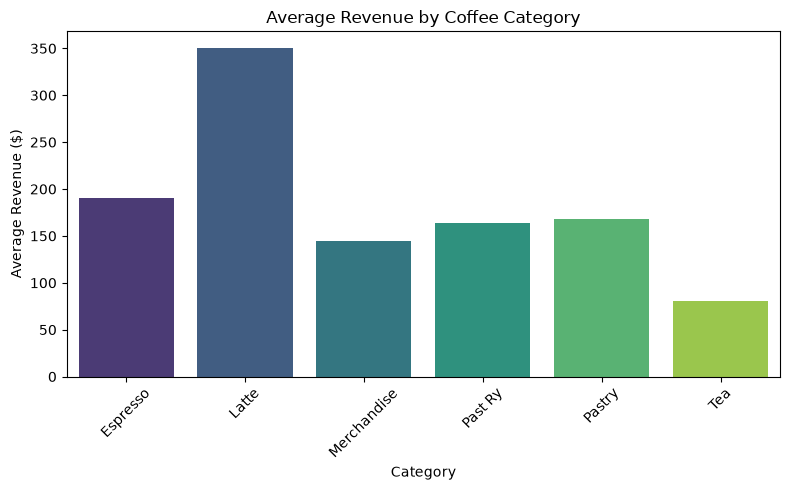

In [29]:
# 4b — your code here
# 4b — Create one chart showing this result visually with a title and axis labels.
plt.figure(figsize=(8, 5))
sns.barplot(data=avg_revenue, x='category_clean', y='revenue', palette='viridis')
plt.title('Average Revenue by Coffee Category')
plt.xlabel('Category')
plt.ylabel('Average Revenue ($)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()




---
## Section 5 — Explain (20%)

Answer each question in 1–3 sentences, directly in the markdown cell provided.


**5a.** Why did you choose the missing-value strategy you used in 2a? What would be a downside of that choice?

*Your answer here:*


Using the median preserves central tendency without being skewed by potential outliers in sales and revenue data. A downside is that imputation artificially reduces variance and ignores relationships between variables (like unit price and quantity sold), which can underestimate standard errors or introduce bias

**5b.** Looking at your Section 3 results: why might the SQL query and the pandas result not match exactly, even though they're answering the same question?

*Your answer here:*


The SQL query executed directly on the raw database table (which still contained duplicates and missing values), whereas the pandas query ran on the cleaned DataFrame after duplicate removal and median imputation.

**5c.** Suppose a manager wanted to use your Section 4 chart to decide which category to promote more heavily next quarter. What is one reason they should be cautious about relying on this chart alone?

*Your answer here:*


Average revenue per transaction/record does not account for total sales volume, profit margins, or promotional costs. A category might have a high average revenue per sale but sell very infrequently, meaning total profit or transaction volume would be a safer metric for promotional decisions.